In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 
import seaborn as sns

In [5]:
data_q1 = [1, 1.75, 2, 3, 3.25, 4]

[Text(0.5, 1.0, 'Q1 ECDF')]

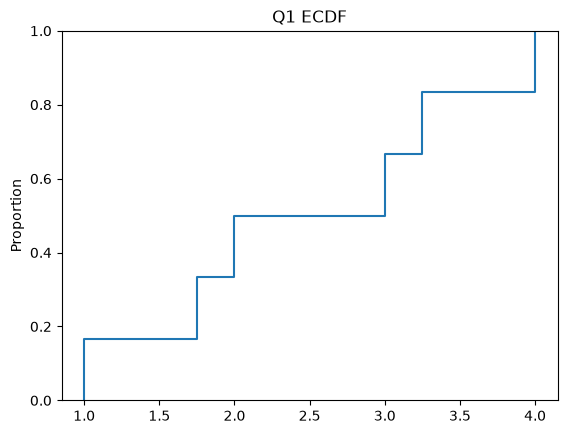

In [12]:
sns.ecdfplot(data_q1).set(title="Q1 ECDF")

In [14]:
def kde_manual_bandwidth(X,K=30, bandwidth=0.2):
    n = len(X)
    X = np.array(X)
    h_u = bandwidth
    x_grid = np.linspace( X.min()-2*h_u, X.max()+2*h_u, K) # Create a grid to plot
    I = np.abs( x_grid[:,None] - X[None,:]) < h_u # Broadcast the indicator comparison
    f_hat = np.sum(I,axis=1)/(2 * n * h_u) # Compute kde
    plt.step(x_grid,f_hat,where='mid')
    plt.fill_between(x_grid,f_hat,step='mid')
    plt.title('Uniform Kernel Density Estimator (Blocky)')
    plt.show()
    return x_grid, f_hat

def kde_silver_bandwidth(X,K=30):
    n = len(X)
    X = np.array(X)
    h_u = 1.84 * X.std() * n ** (-0.2) # Compute bandwidth
    x_grid = np.linspace( X.min()-2*h_u, X.max()+2*h_u, K) # Create a grid to plot
    I = np.abs( x_grid[:,None] - X[None,:]) < h_u # Broadcast the indicator comparison
    f_hat = np.sum(I,axis=1)/(2 * n * h_u) # Compute kde
    plt.step(x_grid,f_hat,where='mid')
    plt.fill_between(x_grid,f_hat,step='mid')
    plt.title('Uniform Kernel Density Estimator (Blocky)')
    plt.show()
    return x_grid, f_hat

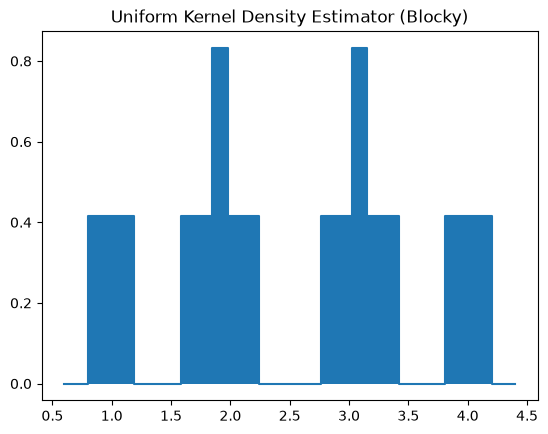

(array([0.6       , 0.73103448, 0.86206897, 0.99310345, 1.12413793,
        1.25517241, 1.3862069 , 1.51724138, 1.64827586, 1.77931034,
        1.91034483, 2.04137931, 2.17241379, 2.30344828, 2.43448276,
        2.56551724, 2.69655172, 2.82758621, 2.95862069, 3.08965517,
        3.22068966, 3.35172414, 3.48275862, 3.6137931 , 3.74482759,
        3.87586207, 4.00689655, 4.13793103, 4.26896552, 4.4       ]),
 array([0.        , 0.        , 0.41666667, 0.41666667, 0.41666667,
        0.        , 0.        , 0.        , 0.41666667, 0.41666667,
        0.83333333, 0.41666667, 0.41666667, 0.        , 0.        ,
        0.        , 0.        , 0.41666667, 0.41666667, 0.83333333,
        0.41666667, 0.41666667, 0.        , 0.        , 0.        ,
        0.41666667, 0.41666667, 0.41666667, 0.        , 0.        ]))

In [15]:
kde_manual_bandwidth(data_q1, bandwidth=0.2)

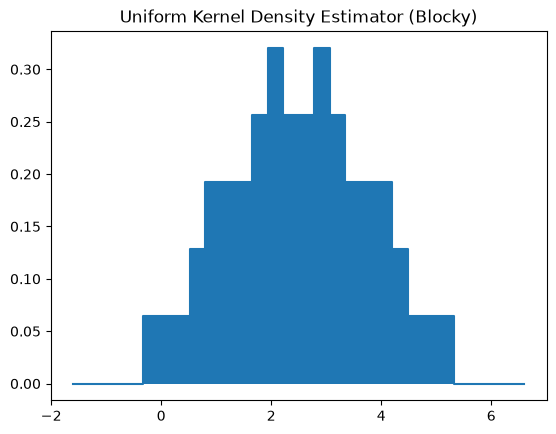

(array([-1.59833408, -1.31569035, -1.03304662, -0.75040289, -0.46775916,
        -0.18511543,  0.0975283 ,  0.38017203,  0.66281576,  0.94545949,
         1.22810322,  1.51074695,  1.79339068,  2.07603441,  2.35867814,
         2.64132186,  2.92396559,  3.20660932,  3.48925305,  3.77189678,
         4.05454051,  4.33718424,  4.61982797,  4.9024717 ,  5.18511543,
         5.46775916,  5.75040289,  6.03304662,  6.31569035,  6.59833408]),
 array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.06414366, 0.06414366, 0.06414366, 0.12828733, 0.19243099,
        0.19243099, 0.19243099, 0.25657465, 0.32071832, 0.25657465,
        0.25657465, 0.32071832, 0.25657465, 0.19243099, 0.19243099,
        0.19243099, 0.12828733, 0.06414366, 0.06414366, 0.06414366,
        0.        , 0.        , 0.        , 0.        , 0.        ]))

In [16]:
kde_silver_bandwidth(data_q1)

In [18]:
def silverman_bandwidth(X, kernel="uniform"):
    """Silverman's rule-of-thumb bandwidth. `kernel` selects the constant."""
    const = {"uniform": 1.84, "gaussian": 1.06}[kernel]
    return const * np.std(X) * len(X) ** (-0.2)


def kde_grid(X, h, pad=2.0, K=200):
    """The evaluation grid shared by every estimator below."""
    X = np.asarray(X)
    return np.linspace(X.min() - pad * h, X.max() + pad * h, K)


def uniform_kde(X, grid, h):
    """f_hat_h(x) on `grid`, uniform kernel. Pure computation, no plotting."""
    X = np.asarray(X)
    n = len(X)
    I = np.abs(grid[:, None] - X[None, :]) < h
    return I.sum(axis=1) / (2 * n * h)


def gaussian_kde(X, grid, h):
    """f_hat_h(x) on `grid`, Gaussian kernel."""
    X = np.asarray(X)
    n = len(X)
    Z = (grid[:, None] - X[None, :]) / h
    phi = np.exp(-Z**2 / 2) / np.sqrt(2 * np.pi)
    return phi.sum(axis=1) / (n * h)


def plot_density(grid, f_hat, **kwargs):
    """One shared plotting routine, reused for both single curves and bump stacks."""
    plt.step(grid, f_hat, where="mid", **kwargs)

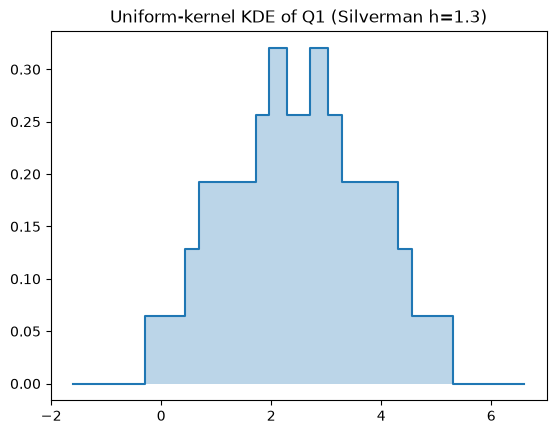

Q1: area under f_hat = 0.9987


In [19]:
# Uniform-kernel KDE on two real columns, using the shared helpers.
X = data_q1
h = silverman_bandwidth(X, "uniform")
grid = kde_grid(X, h)
f_hat = uniform_kde(X, grid, h)

plt.figure()
plot_density(grid, f_hat)
plt.fill_between(grid, f_hat, step="mid", alpha=0.3)
plt.title(f"Uniform-kernel KDE of Q1 (Silverman h={h:.3g})")
plt.show()

print(f"Q1: area under f_hat = {np.trapezoid(f_hat, grid):.4f}")

In [20]:
np.std(data_q1)

np.float64(1.0103629710818451)

In [30]:
data_q2 = [-1.0, -0.5, 0, 0.5, 1.0]
X = np.array(data_q2)
n = len(X)
h_u = 0.6
x_target = 0

f_hat_0 = np.sum(np.abs(x_target - X) < h_u) / (2 * n * h_u)
print(f_hat_0)

0.5


In [36]:
import scipy

scipy.stats.norm.cdf(0.6)

np.float64(0.7257468822499265)

In [37]:
scipy.stats.norm.cdf(-0.6)

np.float64(0.2742531177500736)

In [38]:
scipy.stats.norm.cdf(0)

np.float64(0.5)

In [39]:
scipy.stats.norm.cdf(0.1)

np.float64(0.539827837277029)

In [40]:
scipy.stats.norm.cdf(-0.1)

np.float64(0.460172162722971)